# Selection or impact? Was the gap already there

**Where this ended up, read this first:** started as a selection-vs-impact test on the
overall EJ gap. Chasing down *why* one piece of it moved the way it did led somewhere more
fundamental -- the headline "hosting ZIPs are poorer" finding turns out to depend on a basic
choice (weight every ZIP equally, or every person equally) that flips the answer, once you
account for the fact that hosting ZIPs simply have a much larger minority population share
than non-hosting ZIPs, and poverty is structurally higher for that group everywhere in the
country. That's the real payoff, in "The composition effect" section below. The selection-
vs-impact investigation that got there is kept intact, not rewritten after the fact.

Follow-up to `dc_ej_hosting_gap.ipynb`: that piece established data-center ZIP codes score
worse on EJ burden than non-hosting ZIPs, and the gap survives controlling for population
density. Simon's direct follow-up: how do we know that's data centers *driving down* EJ,
rather than data centers *favoring* already-low-EJ areas? Cross-sectional data genuinely
cannot tell those apart -- a snapshot of "where things are now" looks identical either way.

**What's actually available to test this, checked before building anything:** neither
data-center dataset in the merascope pipeline has a usable opening/construction date --
the small confirmed tracker (`datacenters.db`, 46 sites) has empty date columns, and the
national facilities file (2,302 sites, `data/datacenters/facilities.geojson`) has no
date field at all, only current status. So a clean event-study (EJ before vs. after each
site's actual opening) isn't possible with what's here.

**What IS possible:** merascope's `demog_index` (poverty + minority rate, half of the real
EJ formula) comes from the Census ACS API, which is queryable at older 5-year vintages.
The live pipeline uses 2022 ACS5 (`~2018-2022`); this notebook adds a single national pull
of 2013 ACS5 (`~2009-2013`) for the same ZCTAs, well before the recent hyperscale data-center
boom. That allows a real, if imperfect, test: **was the demographic-vulnerability gap
between hosting and non-hosting ZIPs already present a decade ago, or did it open up more
recently?** If it was already mostly there, that's evidence for selection. If it opened up
mostly since, that's more consistent with impact.

**Real limitations, stated up front, not discovered after publishing:**
- No per-site dates means this can't isolate "before this specific DC" for each ZIP --
  several of today's hosting ZIPs (Quincy, WA dates to ~2007) already had a data center by
  2013 too. This test only speaks to whether the gap grew across the *recent* boom, not
  whether it predates data centers entirely -- a 2013-era gap could itself already reflect
  an earlier round of siting/impact from before this test's own baseline.
- Only the demographic half of `ej_score` can go historical this way. The pollution/hazard
  half (contamination, superfund, RCRA, air quality) is a current EPA snapshot with no
  cheap way to reconstruct history, so this cannot fully replicate `ej_score` -- only
  `demog_index`.
- 2013 ACS5 reports against 2010-vintage ZCTA boundaries; 2022 ACS5 against 2020-vintage
  ones. Joined on the 5-digit ZCTA code (stable across the redefinition for the large
  majority of ZIPs), not re-delineated -- a source of some noise at the margins, not
  corrected for here.

In [1]:
import glob
import json
from pathlib import Path

import numpy as np
import numpy.linalg as la
import pandas as pd
from scipy import stats

# Current (2022 ACS5) demog_index -- already cached per state by the live pipeline
# (scripts/zcta/02_zcta_indicators.py's fetch_acs_zcta), no need to refetch.
frames = [pd.read_csv(p, dtype={"zcta": str}) for p in
          glob.glob("../../merascope/data/*/zcta/acs_demog.csv")]
demog_now = pd.concat(frames, ignore_index=True).drop_duplicates("zcta")
demog_now["zcta"] = demog_now["zcta"].str.zfill(5)
print(f"current (2022 ACS5) demog_index: {len(demog_now)} ZCTAs")

# 2013 ACS5, same variables/formula as fetch_acs_zcta, just an older vintage and a single
# national wildcard call (cached to data/ so this notebook is re-runnable without refetching).
RAW_2013 = Path("data/acs_zcta_2013_raw.json")
if not RAW_2013.exists():
    import requests
    key = None
    for env_file in [Path("../../merascope/.env"), Path("../../snotrac/.env"), Path.home() / ".env"]:
        if env_file.exists():
            for line in env_file.read_text().splitlines():
                if line.startswith("CENSUS_API_KEY"):
                    key = line.split("=", 1)[1].strip()
    params = {"get": "NAME,B17001_001E,B17001_002E,B02001_001E,B02001_002E,B01003_001E",
              "for": "zip code tabulation area:*", "key": key}
    r = requests.get("https://api.census.gov/data/2013/acs/acs5", params=params, timeout=180)
    r.raise_for_status()
    RAW_2013.parent.mkdir(parents=True, exist_ok=True)
    RAW_2013.write_text(r.text)

raw = json.loads(RAW_2013.read_text())
df13 = pd.DataFrame(raw[1:], columns=raw[0])
for c in ["B17001_001E", "B17001_002E", "B02001_001E", "B02001_002E", "B01003_001E"]:
    df13[c] = pd.to_numeric(df13[c], errors="coerce")
df13["zcta"] = df13["zip code tabulation area"].astype(str).str.zfill(5)
df13["poverty_rate"] = (df13["B17001_002E"] / df13["B17001_001E"]).clip(0, 1)
df13["minority_rate"] = (1 - df13["B02001_002E"] / df13["B02001_001E"]).clip(0, 1)
df13["demog_index_2013"] = (df13["poverty_rate"] + df13["minority_rate"]) / 2
df13 = df13[["zcta", "demog_index_2013"]].dropna()
print(f"2013 ACS5 demog_index: {len(df13)} ZCTAs")

# has_dc + density (same real hosting label and density measure as dc_ej_hosting_gap.ipynb)
mt = pd.read_csv("../../merascope/notebooks/cache/model_table.csv", dtype={"zcta": str})
lab = pd.read_csv("../../merascope/data/datacenters/zcta_labels.csv", dtype={"zcta": str})
mt = mt.merge(lab, on="zcta", how="left")
for c in ["n_built", "has_dc"]:
    mt[c] = mt[c].fillna(0).astype(int)

d = (mt[["zcta", "has_dc", "pop_exposure_score"]]
     .merge(demog_now[["zcta", "demog_index"]].rename(columns={"demog_index": "demog_index_now"}),
            on="zcta", how="inner")
     .merge(df13, on="zcta", how="inner"))
d["density_axis"] = 1 - d["pop_exposure_score"]
d = d.dropna(subset=["demog_index_now", "demog_index_2013", "density_axis"]).copy()
d["delta"] = d["demog_index_now"] - d["demog_index_2013"]

print(f"\n{len(d)} ZCTAs with both vintages, {int(d['has_dc'].sum())} hosting a confirmed built facility")
assert len(d) > 30000, "unexpectedly large join loss between the two ACS vintages -- check the merge"

current (2022 ACS5) demog_index: 33252 ZCTAs
2013 ACS5 demog_index: 32587 ZCTAs

31762 ZCTAs with both vintages, 1181 hosting a confirmed built facility


## Was the gap already there in 2013?

`demog_index` is the OPPOSITE sign convention from `ej_score` -- **higher = MORE
vulnerable** (more poverty/minority population), not less. Kept as-is (not flipped) so it
matches the pipeline's own variable name and formula exactly.

In [2]:
host, non = d[d.has_dc == 1], d[d.has_dc == 0]

baseline_gap = host["demog_index_2013"].mean() - non["demog_index_2013"].mean()
current_gap = host["demog_index_now"].mean() - non["demog_index_now"].mean()
_, p_base = stats.mannwhitneyu(host["demog_index_2013"], non["demog_index_2013"])
_, p_cur = stats.mannwhitneyu(host["demog_index_now"], non["demog_index_now"])

print("demog_index (0-1, higher = more vulnerable):")
print(f"  2013 (baseline): hosting={host['demog_index_2013'].mean():.4f}  non-hosting={non['demog_index_2013'].mean():.4f}  "
      f"gap={baseline_gap:+.4f}  (p={p_base:.1e})")
print(f"  2022 (current):  hosting={host['demog_index_now'].mean():.4f}  non-hosting={non['demog_index_now'].mean():.4f}  "
      f"gap={current_gap:+.4f}  (p={p_cur:.1e})")

frac_already_there = baseline_gap / current_gap
print(f"\n{frac_already_there*100:.1f}% of today's gap was already present in 2013 -- "
      f"{'a decade before the recent hyperscale boom' if frac_already_there > 0.5 else ''}")

assert baseline_gap > 0 and p_base < 0.001, "expected a real, already-present gap in 2013"
assert current_gap > baseline_gap, "expected the gap to have widened somewhat by 2022, not shrunk"
assert frac_already_there > 0.5, "if less than half the gap predates 2013, selection isn't the dominant story -- recheck before claiming it"
print("\nMost of the gap predates the recent DC boom -- consistent with selection (siting into")
print("already-vulnerable areas), not proof that data centers are driving demographic change.")

demog_index (0-1, higher = more vulnerable):
  2013 (baseline): hosting=0.2096  non-hosting=0.1495  gap=+0.0601  (p=4.1e-86)
  2022 (current):  hosting=0.2328  non-hosting=0.1639  gap=+0.0689  (p=1.3e-108)

87.2% of today's gap was already present in 2013 -- a decade before the recent hyperscale boom

Most of the gap predates the recent DC boom -- consistent with selection (siting into
already-vulnerable areas), not proof that data centers are driving demographic change.


## Did the gap widen faster in hosting ZIPs -- controlling for density and baseline level?

The small residual (today's gap minus 2013's gap) could still be a real, if modest, signal
consistent with impact. Tested properly: regress the 9-year *change* in `demog_index` on
`has_dc`, controlling for `density_axis` (denser ZIPs generically saw more demographic change
over this decade, unrelated to data centers) and the 2013 baseline level itself (mean
reversion -- ZIPs that started more extreme regress toward the middle regardless of anything
else). A permutation test on the `has_dc` coefficient, not just a t-stat, same discipline as
`dc_ej_hosting_gap.ipynb`.

In [3]:
def ols(y, X):
    X1 = np.column_stack([np.ones(len(X)), X])
    beta, *_ = la.lstsq(X1, y, rcond=None)
    resid = y - X1 @ beta
    dof = len(y) - X1.shape[1]
    sigma2 = (resid @ resid) / dof
    se = np.sqrt(np.diag(sigma2 * la.inv(X1.T @ X1)))
    return beta, beta / se


y = d["delta"].to_numpy()
has_dc = d["has_dc"].to_numpy().astype(float)
X = d[["density_axis", "demog_index_2013"]].to_numpy().astype(float)
beta, t = ols(y, np.column_stack([has_dc, X]))

print(f"delta_demog_index ~ has_dc + density_axis + demog_index_2013:")
print(f"  has_dc coef      = {beta[1]:+.4f}  (t={t[1]:.2f})")
print(f"  density_axis     = {beta[2]:+.4f}  (t={t[2]:.2f})  -- denser ZIPs generically drifted more vulnerable")
print(f"  demog_index_2013 = {beta[3]:+.4f}  (t={t[3]:.2f})  -- mean reversion, as expected")

rng = np.random.RandomState(0)
N_PERM = 200
null = np.empty(N_PERM)
for i in range(N_PERM):
    shuf = rng.permutation(has_dc)
    b, _ = ols(y, np.column_stack([shuf, X]))
    null[i] = b[1]  # b[0] is the intercept -- b[1] is the shuffled has_dc coefficient
p_perm = (np.sum(np.abs(null) >= abs(beta[1])) + 1) / (N_PERM + 1)
print(f"\n200-shuffle permutation null on the has_dc coefficient: mean={null.mean():+.4f}, "
      f"std={null.std():.4f}, p={p_perm:.4f}")

assert p_perm < 0.05, "the residual widening doesn't clear a permutation null -- don't claim it as real"
print(f"\nReal but small: hosting ZIPs' demographic vulnerability grew "
      f"{beta[1]:.4f} points more than density- and baseline-matched non-hosting ZIPs over "
      f"9 years -- about {beta[1]/current_gap*100:.0f}% of today's total gap. Statistically real, "
      f"nowhere near the dominant explanation.")

delta_demog_index ~ has_dc + density_axis + demog_index_2013:
  has_dc coef      = +0.0070  (t=3.11)
  density_axis     = +0.0461  (t=28.37)  -- denser ZIPs generically drifted more vulnerable
  demog_index_2013 = -0.1886  (t=-56.27)  -- mean reversion, as expected

200-shuffle permutation null on the has_dc coefficient: mean=-0.0001, std=0.0022, p=0.0050

Real but small: hosting ZIPs' demographic vulnerability grew 0.0070 points more than density- and baseline-matched non-hosting ZIPs over 9 years -- about 10% of today's total gap. Statistically real, nowhere near the dominant explanation.


## Is the growth smooth, or concentrated in one confounded window?

Simon's follow-up, twice: the gap predating 2013 doesn't rule out an ongoing effect -- we
already showed the gap wider in 2022 than 2013, can we show it actually growing, not just two
noisy endpoints? Pulled every annual ACS 5-year vintage from 2011 (the earliest year ZCTA
geography is available at this API endpoint -- 2009 and 2010 both return "unsupported
geography hierarchy") through 2022, 12 points instead of 2, with a bootstrap 95% CI on each
one so the chart shows real uncertainty instead of connecting dots that might just be noise.

**A real confound turned up, and it lines up almost exactly with the years that "grow."** The
2020, 2021, and 2022 ACS 5-year vintages all include 2020 data collection. COVID-era
nonresponse was severe enough that the Census Bureau switched to a different weighting
method (entropy-balancing) for the 2020 portion of those vintages specifically, and its own
guidance explicitly cautions against comparing any vintage that includes 2020 to one that
doesn't -- see "Comparing ACS Data" and the 2012-2016-vs-2017-2021 comparison guidance,
both at census.gov. That means the three most recent points on this chart carry a real,
named reason to distrust them relative to the rest, not just generic sampling noise -- flagged
visually on the chart (shaded band, hollow markers) rather than left for a caption footnote.

In [4]:
ALL_YEARS = list(range(2011, 2023))
COVID_YEARS = {2020, 2021, 2022}  # 5-year window includes 2020 ACS data collection


def load_acs_vintage(year):
    if year == 2022:
        return demog_now.rename(columns={"demog_index": f"demog_{year}"})[["zcta", f"demog_{year}"]]
    raw_path = Path(f"data/acs_zcta_{year}_raw.json")
    raw = json.loads(raw_path.read_text())
    df = pd.DataFrame(raw[1:], columns=raw[0])
    for c in ["B17001_001E", "B17001_002E", "B02001_001E", "B02001_002E", "B01003_001E"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df["zcta"] = df["zip code tabulation area"].astype(str).str.zfill(5)
    df["poverty_rate"] = (df["B17001_002E"] / df["B17001_001E"]).clip(0, 1)
    df["minority_rate"] = (1 - df["B02001_002E"] / df["B02001_001E"]).clip(0, 1)
    df[f"demog_{year}"] = (df["poverty_rate"] + df["minority_rate"]) / 2
    return df[["zcta", f"demog_{year}"]].dropna()


wide = d[["zcta", "has_dc", "density_axis"]].copy()
for yr in ALL_YEARS:
    wide = wide.merge(load_acs_vintage(yr), on="zcta", how="inner")
demog_cols = [f"demog_{yr}" for yr in ALL_YEARS]
wide = wide.dropna(subset=demog_cols).copy()
print(f"{len(wide)} ZCTAs present in all 12 annual vintages, {int(wide['has_dc'].sum())} hosting")

host_w, non_w = wide[wide.has_dc == 1], wide[wide.has_dc == 0]
rng2 = np.random.RandomState(1)
N_BOOT = 1000
yearly = []
for yr in ALL_YEARS:
    hv, nv = host_w[f"demog_{yr}"].to_numpy(), non_w[f"demog_{yr}"].to_numpy()
    gap = hv.mean() - nv.mean()
    boot = np.array([rng2.choice(hv, len(hv), replace=True).mean()
                      - rng2.choice(nv, len(nv), replace=True).mean() for _ in range(N_BOOT)])
    lo, hi = np.percentile(boot, [2.5, 97.5])
    yearly.append({"year": yr, "gap": gap, "ci_lo": lo, "ci_hi": hi, "covid": yr in COVID_YEARS})
yearly = pd.DataFrame(yearly)
print(yearly.round(4).to_string(index=False))

pre_covid = yearly[~yearly.covid]
print(f"\n2011-2019 (pre-COVID vintages): gap ranges {pre_covid['gap'].min():.4f} to "
      f"{pre_covid['gap'].max():.4f} -- flat, every year's 95% CI overlaps every other year's.")
print(f"2019 -> 2022: gap moves {yearly[yearly.year==2019]['gap'].iloc[0]:.4f} -> "
      f"{yearly[yearly.year==2022]['gap'].iloc[0]:.4f}, entirely within the 3 COVID-flagged vintages.")

assert pre_covid["gap"].max() - pre_covid["gap"].min() < 0.003, \
    "pre-COVID years should be flat (tight range) -- recheck if this trips"
print("\nHonest read: no evidence of a smooth ongoing widening. What growth exists is entirely")
print("concentrated in the exact years the Census Bureau itself flags as methodologically")
print("distinct -- consistent with either a real recent acceleration (the actual DC boom did")
print("speed up around the same time) or a measurement artifact. Cannot tell those apart here.")

31495 ZCTAs present in all 12 annual vintages, 1179 hosting
 year    gap  ci_lo  ci_hi  covid
 2011 0.0590 0.0506 0.0664  False
 2012 0.0600 0.0525 0.0679  False
 2013 0.0603 0.0526 0.0685  False
 2014 0.0604 0.0525 0.0678  False
 2015 0.0607 0.0533 0.0686  False
 2016 0.0604 0.0531 0.0678  False
 2017 0.0594 0.0519 0.0670  False
 2018 0.0592 0.0524 0.0664  False
 2019 0.0592 0.0524 0.0666  False
 2020 0.0610 0.0545 0.0683   True
 2021 0.0650 0.0572 0.0723   True
 2022 0.0690 0.0620 0.0762   True

2011-2019 (pre-COVID vintages): gap ranges 0.0590 to 0.0607 -- flat, every year's 95% CI overlaps every other year's.
2019 -> 2022: gap moves 0.0592 -> 0.0690, entirely within the 3 COVID-flagged vintages.

Honest read: no evidence of a smooth ongoing widening. What growth exists is entirely
concentrated in the exact years the Census Bureau itself flags as methodologically
distinct -- consistent with either a real recent acceleration (the actual DC boom did
speed up around the same time) or a

## Is the COVID-vintage rise just noisier data, or something else?

Simon pushed further: "methodology change" sounds like it could just mean "COVID happened" --
what specifically changed, and can we test it? Dug into the actual mechanism: 2020 ACS
response rates dropped by a third, and nonresponse was NOT random -- lower-income,
lower-education, non-homeowner households were specifically less likely to respond. Left
uncorrected, that biases poverty estimates DOWN (the opposite direction from what we're
seeing), because the people who did respond skewed richer. The Census Bureau's fix
("entropy balancing") reweights respondents against IRS administrative income data --
available for non-respondents too -- to correct for exactly that skew, and their own
validation showed it works: a naive 5.5% jump in median household income (2019->2020)
became a 0.2% jump once corrected. **The published 2020-2022 vintages already carry this**
**correction** -- not the raw biased numbers.

That still leaves a real, testable question: is the correction equally reliable at ZCTA
resolution (it was validated mainly at state/national level), and did it land differently on
hosting vs. non-hosting ZIPs? One piece of that IS checkable with public data: ACS estimates
ship with margins of error precisely so reliability can be checked instead of assumed. If the
correction were making 2020-2022 ZCTA estimates noisier, that should show up as a wider
coefficient of variation (CV = MOE / estimate) in those years specifically -- same discipline
as `feedback_acs_small_area_reliability` elsewhere in this workspace: check MOE before
trusting a small-area estimate, don't find out after publishing.

In [5]:
def load_moe_vintage(year):
    raw_path = Path(f"data/acs_zcta_{year}_moe_raw.json")
    raw = json.loads(raw_path.read_text())
    mdf = pd.DataFrame(raw[1:], columns=raw[0])
    moe_cols = ["B17001_001E", "B17001_001M", "B17001_002E", "B17001_002M",
                "B02001_001E", "B02001_001M", "B02001_002E", "B02001_002M"]
    for c in moe_cols:
        mdf[c] = pd.to_numeric(mdf[c], errors="coerce")
    mdf["zcta"] = mdf["zip code tabulation area"].astype(str).str.zfill(5)

    # Standard Census ratio-MOE formula (ACS General Handbook, Appendix A) for a proportion
    # p = X/Y where X is a subset of Y -- poverty_rate and (1 - white-alone share) both qualify.
    def ratio_moe(num_e, num_m, den_e, den_m):
        p = num_e / den_e
        under = num_m**2 - (p**2 * den_m**2)
        moe = np.where(under >= 0, np.sqrt(under.clip(lower=0)),
                        np.sqrt(num_m**2 + (p**2 * den_m**2))) / den_e
        return p, moe

    pov_rate, pov_moe = ratio_moe(mdf["B17001_002E"], mdf["B17001_002M"], mdf["B17001_001E"], mdf["B17001_001M"])
    white_share, white_moe = ratio_moe(mdf["B02001_002E"], mdf["B02001_002M"], mdf["B02001_001E"], mdf["B02001_001M"])
    demog = (pov_rate.clip(0, 1) + (1 - white_share).clip(0, 1)) / 2
    demog_moe = np.sqrt(pov_moe**2 + white_moe**2) / 2  # independent-variance combination, same average structure as demog_index itself
    cv = (demog_moe / 1.645) / demog.replace(0, np.nan)
    mdf[f"demog_{year}_cv"] = cv
    return mdf[["zcta", f"demog_{year}_cv"]]


cv_wide = d[["zcta", "has_dc"]].copy()
for yr in ALL_YEARS:
    cv_wide = cv_wide.merge(load_moe_vintage(yr), on="zcta", how="inner")
cv_wide = cv_wide.dropna(subset=[f"demog_{yr}_cv" for yr in ALL_YEARS]).copy()
print(f"{len(cv_wide)} ZCTAs with MOE data in all 12 vintages")

host_cv, non_cv = cv_wide[cv_wide.has_dc == 1], cv_wide[cv_wide.has_dc == 0]
cv_table = pd.DataFrame({
    "year": ALL_YEARS,
    "median_cv_hosting": [host_cv[f"demog_{y}_cv"].median() for y in ALL_YEARS],
    "median_cv_nonhosting": [non_cv[f"demog_{y}_cv"].median() for y in ALL_YEARS],
    "covid": [y in COVID_YEARS for y in ALL_YEARS],
})
print(cv_table.round(4).to_string(index=False))

pre_cv_host = cv_table.loc[~cv_table.covid, "median_cv_hosting"]
covid_cv_host = cv_table.loc[cv_table.covid, "median_cv_hosting"]
pre_cv_non = cv_table.loc[~cv_table.covid, "median_cv_nonhosting"]
covid_cv_non = cv_table.loc[cv_table.covid, "median_cv_nonhosting"]

assert covid_cv_host.max() <= pre_cv_host.max() * 1.15, \
    "COVID-vintage CV clearly worse than any pre-COVID year for hosting ZIPs -- reliability concern is real, say so"
assert covid_cv_non.max() <= pre_cv_non.max() * 1.15, \
    "COVID-vintage CV clearly worse than any pre-COVID year for non-hosting ZIPs -- reliability concern is real, say so"
print(f"\nCOVID-vintage CVs sit inside the normal pre-COVID range for both groups -- 2021 and 2022")
print(f"are actually MORE reliable by this measure than 2011-2013 were. No sign that the entropy-")
print(f"balance correction made ZCTA-level estimates noisier, for hosting or non-hosting ZIPs.")
print(f"\nThis doesn't clear the correction of everything -- MOE only captures RANDOM sampling")
print(f"uncertainty, not a SYSTEMATIC bias the correction model itself might introduce (over- or")
print(f"under-correcting some geography types). But 'the 2020+ numbers are just noisier, don't")
print(f"read too much into them' is not supported by the data the Census Bureau itself publishes")
print(f"to make that exact judgment call -- the rise deserves to be taken seriously, not waved off.")

29471 ZCTAs with MOE data in all 12 vintages
 year  median_cv_hosting  median_cv_nonhosting  covid
 2011             0.0699                0.2050  False
 2012             0.0683                0.1990  False
 2013             0.0655                0.1935  False
 2014             0.0653                0.1889  False
 2015             0.0639                0.1866  False
 2016             0.0621                0.1862  False
 2017             0.0620                0.1889  False
 2018             0.0616                0.1888  False
 2019             0.0636                0.1927  False
 2020             0.0664                0.2032   True
 2021             0.0652                0.1964   True
 2022             0.0630                0.1874   True

COVID-vintage CVs sit inside the normal pre-COVID range for both groups -- 2021 and 2022
are actually MORE reliable by this measure than 2011-2013 were. No sign that the entropy-
balance correction made ZCTA-level estimates noisier, for hosting or non-

## This isn't only a COVID-years problem

Simon's next catch, and a real one: singling out 2020-2022 implied 2011-2019 was a verified
clean baseline. It wasn't verified -- it was just unflagged. Those aren't the same thing, and
the actual national ACS housing-unit response rate makes that concrete:

| Year | Response rate |
|---|---|
| 2011 | 97.6% |
| 2012 | 97.3% |
| 2013 | 89.9% (2013 government shutdown) |
| 2014 | 96.7% |
| 2015 | 95.8% |
| 2016 | 94.7% |
| 2017 | 93.7% |
| 2018 | 92.0% |
| 2019 | 86.0% (2018-2019 government shutdown) |

(Source: [Census.gov ACS response rates](https://www.census.gov/acs/www/methodology/sample-size-and-data-quality/response-rates/).)
Excluding the two shutdown-year outliers, response fell steadily -- 97.6% to 92.0%, a real
~5.6-point decline over seven years -- and survey-methods research generally finds this kind
of decline is not random: harder-to-reach and lower-income households drop out
disproportionately, the same *direction* of bias mechanism as the 2020 COVID case, just
gradual and never given an equivalent correction. So "2011-2019 is the clean baseline, 2020-
2022 is the caveated window" overstates the contrast. The honest version: **the entire
ACS-based comparison, across all 12 years, carries some uncertainty from response-rate change
that this analysis cannot fully separate from real demographic change** -- 2020-2022 is the
most severe and the only *explicitly corrected and flagged* instance of it, not the only
instance.

One partial, genuinely reassuring data point already in hand: the CV table above does NOT
track the declining response rate -- hosting-ZIP CV drifts from 0.070 (2011) down to 0.062
(2018) even as response rate fell from 97.6% to 92.0% over the same years, meaning the
*standard* weighting adjustments (unlike a naive unweighted average) aren't visibly losing
precision as response falls. That's evidence against a strong, sampling-noise-driven version
of this problem. It's not evidence against a systematic one -- the same limit as before,
now understood to apply to the whole series, not just three years of it.

## Wait -- why is the poverty half declining at all?

Splitting `demog_index` into its two ingredients (a separate investigation, not shown as its
own section here) turned up something odd: the *poverty_rate* gap between hosting and
non-hosting ZIPs has been shrinking for the whole decade -- unrelated to COVID, unrelated to
the response-rate story above. Checked against real national poverty history first (Census's
own reporting: poverty was elevated through the slow Great Recession recovery, peaked around
2013-2014, then fell three straight years 2015-2017 and kept falling through 2019) -- the
shape matches exactly, in both groups. Real macro history, not a reporting artifact. But
*why does hosting's poverty fall faster, narrowing the gap specifically*? Simon's hypothesis,
worth taking seriously rather than waving at: are minorities specifically being lifted out of
poverty in data-center ZIPs?

That's directly testable. ACS publishes poverty status broken out by race
(`B17001A` = poverty status, White alone, regardless of Hispanic origin) -- subtracting that
from the total poverty table gives a real, non-inferred minority poverty rate, not a guess
stitched together from two separate aggregates that were never crossed.

In [6]:
def load_race_poverty(year):
    """Total + White-alone poverty counts for one vintage, kept as BOTH raw counts and
    derived rates (both year-suffixed) so per-ZIP-mean and population-weighted aggregation
    can both be computed later from this single load -- no redundant refetching."""
    raw = json.loads(Path(f"data/acs_zcta_{year}_moe_raw.json").read_text())
    tot = pd.DataFrame(raw[1:], columns=raw[0])
    for c in ["B17001_001E", "B17001_002E"]:
        tot[c] = pd.to_numeric(tot[c], errors="coerce")
    tot["zcta"] = tot["zip code tabulation area"].astype(str).str.zfill(5)
    tot = tot[["zcta", "B17001_001E", "B17001_002E"]]

    raw_w = json.loads(Path(f"data/acs_zcta_{year}_racepov_raw.json").read_text())
    wht = pd.DataFrame(raw_w[1:], columns=raw_w[0])
    for c in ["B17001A_001E", "B17001A_002E"]:
        wht[c] = pd.to_numeric(wht[c], errors="coerce")
    wht["zcta"] = wht["zip code tabulation area"].astype(str).str.zfill(5)
    wht = wht[["zcta", "B17001A_001E", "B17001A_002E"]]

    m = tot.merge(wht, on="zcta", how="inner")
    m["min_pop"] = m["B17001_001E"] - m["B17001A_001E"]
    m["min_povcnt"] = m["B17001_002E"] - m["B17001A_002E"]
    m["pov_rate"] = (m["B17001_002E"] / m["B17001_001E"]).clip(0, 1)
    m["wht_povrate"] = (m["B17001A_002E"] / m["B17001A_001E"]).clip(0, 1)
    m["min_povrate"] = (m["min_povcnt"] / m["min_pop"]).clip(0, 1)
    m["min_share"] = (m["min_pop"] / m["B17001_001E"]).clip(0, 1)
    keep = ["B17001_001E", "B17001_002E", "B17001A_001E", "B17001A_002E", "min_pop",
            "min_povcnt", "pov_rate", "wht_povrate", "min_povrate", "min_share"]
    return m[["zcta"] + keep].dropna().rename(columns={c: f"{c}_{year}" for c in keep})


race_wide = d[["zcta", "has_dc"]].copy()
for yr in ALL_YEARS:
    race_wide = race_wide.merge(load_race_poverty(yr), on="zcta", how="inner")
print(f"{len(race_wide)} ZCTAs with race-specific poverty data in all 12 vintages")

rhost, rnon = race_wide[race_wide.has_dc == 1], race_wide[race_wide.has_dc == 0]
print("\nyear  white_gap  minority_gap  minority_SHARE_gap   (per-ZIP-mean, same convention as this whole piece)")
for yr in ALL_YEARS:
    wg = rhost[f"wht_povrate_{yr}"].mean() - rnon[f"wht_povrate_{yr}"].mean()
    mg = rhost[f"min_povrate_{yr}"].mean() - rnon[f"min_povrate_{yr}"].mean()
    sg = rhost[f"min_share_{yr}"].mean() - rnon[f"min_share_{yr}"].mean()
    print(f"{yr}  {wg:+.4f}    {mg:+.4f}       {sg:+.4f}")

assert abs(rhost[[f"wht_povrate_{y}" for y in ALL_YEARS]].mean().mean()
           - rnon[[f"wht_povrate_{y}" for y in ALL_YEARS]].mean().mean()) < 0.01, \
    "expected within-race poverty gaps to be small, near parity -- recheck if this trips"
print("\nWithin each race, hosting and non-hosting ZIPs are close to parity on poverty -- never more")
print("than about a point apart, no economic edge either direction. The minority SHARE gap is an")
print("order of magnitude bigger. That is NOT 'minorities being lifted out of poverty in hosting")
print("ZIPs' -- there's no within-group difference to lift. It's that hosting ZIPs simply have a much")
print("larger minority population share, and minority poverty is structurally higher than white")
print("poverty everywhere in the country, for reasons that have nothing to do with data centers.")

24874 ZCTAs with race-specific poverty data in all 12 vintages

year  white_gap  minority_gap  minority_SHARE_gap   (per-ZIP-mean, same convention as this whole piece)
2011  +0.0083    +0.0026       +0.0795
2012  +0.0084    +0.0045       +0.0803
2013  +0.0079    +0.0040       +0.0809
2014  +0.0079    +0.0033       +0.0814
2015  +0.0068    +0.0020       +0.0825
2016  +0.0064    +0.0026       +0.0830
2017  +0.0052    +0.0022       +0.0829
2018  +0.0039    -0.0016       +0.0839
2019  +0.0036    -0.0061       +0.0850
2020  +0.0024    -0.0081       +0.0892
2021  +0.0013    -0.0075       +0.0966
2022  +0.0025    -0.0056       +0.1034

Within each race, hosting and non-hosting ZIPs are close to parity on poverty -- never more
than about a point apart, no economic edge either direction. The minority SHARE gap is an
order of magnitude bigger. That is NOT 'minorities being lifted out of poverty in hosting
ZIPs' -- there's no within-group difference to lift. It's that hosting ZIPs simply have a m

## The composition effect -- and a real methodological trap underneath it

Formal version of the same point, a standard decomposition (Kitagawa/Blinder-Oaxaca style):
split the overall poverty gap into a **composition effect** (how much comes purely from
hosting ZIPs having a different racial mix, holding poverty rates fixed) and a **rate effect**
(how much comes from actual within-race poverty-rate differences, holding composition fixed).

```
counterfactual = hosting's own within-race poverty rates, applied to non-hosting's composition
composition_effect = actual_hosting_rate - counterfactual
rate_effect         = counterfactual - actual_non_hosting_rate
```

**A real trap turned up building this, not after publishing it:** the decomposition is only
*exactly* self-consistent (composition + rate = total gap, no leftover) under **population-
weighted** rates (every person counted once). Under the **per-ZIP-mean** convention this whole
piece has used throughout (every ZIP counted once, regardless of size), the two effects don't
sum back to the directly-computed gap exactly -- a real artifact of averaging ratios before
combining them, not a bug in the arithmetic. Both are computed below, honestly, rather than
picking whichever one reconciles more cleanly.

**Split further, by race, on Simon's ask.** `rate_effect` already IS a sum of a white piece and
a minority piece: `rate_effect = (1-share_non)*white_gap + share_non*minority_gap`, so that one
splits cleanly. `composition_effect = (share_host - share_non) * (minority_rate_host -`
`white_rate_host)` is a *product*, not a sum, so it does not split into independent white/
minority pieces the same obvious way -- but it can be expanded (`(s_h-s_n)(m_h-w_h) =`
`m_h(s_h-s_n) - w_h(s_h-s_n)`) into two terms that DO sum back to it exactly: how much comes
from minority poverty being counted at a larger population share, and how much comes from
white poverty being counted at a correspondingly smaller one. Both splits verified to sum back
to their parent effect exactly, not just plotted and hoped.

In [7]:
def decompose(df_host, df_non, year, weighted):
    if weighted:
        wh_ = df_host[f"B17001A_002E_{year}"].sum() / df_host[f"B17001A_001E_{year}"].sum()
        wn_ = df_non[f"B17001A_002E_{year}"].sum() / df_non[f"B17001A_001E_{year}"].sum()
        mh_ = df_host[f"min_povcnt_{year}"].sum() / df_host[f"min_pop_{year}"].sum()
        mn_ = df_non[f"min_povcnt_{year}"].sum() / df_non[f"min_pop_{year}"].sum()
        sh_ = df_host[f"min_pop_{year}"].sum() / df_host[f"B17001_001E_{year}"].sum()
        sn_ = df_non[f"min_pop_{year}"].sum() / df_non[f"B17001_001E_{year}"].sum()
        actual_host = df_host[f"B17001_002E_{year}"].sum() / df_host[f"B17001_001E_{year}"].sum()
        actual_non = df_non[f"B17001_002E_{year}"].sum() / df_non[f"B17001_001E_{year}"].sum()
    else:
        wh_, wn_ = df_host[f"wht_povrate_{year}"].mean(), df_non[f"wht_povrate_{year}"].mean()
        mh_, mn_ = df_host[f"min_povrate_{year}"].mean(), df_non[f"min_povrate_{year}"].mean()
        sh_, sn_ = df_host[f"min_share_{year}"].mean(), df_non[f"min_share_{year}"].mean()
        actual_host = df_host[f"pov_rate_{year}"].mean()
        actual_non = df_non[f"pov_rate_{year}"].mean()

    # Composition effect, split exactly: (sh-sn)*(mh-wh) = minority_comp + white_comp
    minority_comp = mh_ * (sh_ - sn_)
    white_comp = -wh_ * (sh_ - sn_)
    comp = minority_comp + white_comp

    # Rate effect, split exactly: (1-sn)*white_gap + sn*minority_gap
    white_rate = (1 - sn_) * (wh_ - wn_)
    minority_rate = sn_ * (mh_ - mn_)
    rate = white_rate + minority_rate

    total = actual_host - actual_non
    return {"total": total, "comp": comp, "rate": rate, "white_comp": white_comp,
            "minority_comp": minority_comp, "white_rate": white_rate, "minority_rate": minority_rate}


results = []
for yr in ALL_YEARS:
    r_pz = decompose(rhost, rnon, yr, weighted=False)
    r_pw = decompose(rhost, rnon, yr, weighted=True)
    row = {"year": yr}
    row.update({f"{k}_perzip": v for k, v in r_pz.items()})
    row.update({f"{k}_popwtd": v for k, v in r_pw.items()})
    results.append(row)
decomp = pd.DataFrame(results)
decomp = decomp.rename(columns={"total_perzip": "gap_perzip", "total_popwtd": "gap_popwtd"})
print(decomp[["year", "gap_perzip", "comp_perzip", "rate_perzip", "gap_popwtd", "comp_popwtd", "rate_popwtd"]]
      .round(4).to_string(index=False))

# Per-ZIP-mean: comp+rate reconciles to the DIRECTLY-COMPUTED gap only approximately.
# The direct gap comes from averaging each ZIP's own poverty RATIO; the race-reconstructed
# comp+rate comes from averaging separate white/minority ratios and shares, then combining.
# Averaging ratios first vs. combining-then-implying-a-ratio don't commute (Jensen's-gap-style
# covariance term), so a real residual survives -- up to ~17% of the gap, not a bug.
perzip_residual = (decomp["comp_perzip"] + decomp["rate_perzip"] - decomp["gap_perzip"]).abs()
perzip_residual_pct = (perzip_residual / decomp["gap_perzip"].abs()).max() * 100
assert perzip_residual.max() < 0.003, f"per-ZIP-mean residual larger than expected: {perzip_residual.max()}"
print(f"\nPer-ZIP-mean reconciliation residual (averaging-ratios artifact, not a bug): "
      f"up to {perzip_residual_pct:.1f}% of the gap across years.")

# Population-weighted: this one IS exact by construction (weighted sums of counts, not
# an average of ratios), so it must reconcile exactly.
assert (decomp["comp_popwtd"] + decomp["rate_popwtd"] - decomp["gap_popwtd"]).abs().max() < 1e-9
assert (decomp["white_comp_perzip"] + decomp["minority_comp_perzip"] - decomp["comp_perzip"]).abs().max() < 1e-9
assert (decomp["white_rate_perzip"] + decomp["minority_rate_perzip"] - decomp["rate_perzip"]).abs().max() < 1e-9
assert (decomp["white_comp_popwtd"] + decomp["minority_comp_popwtd"] - decomp["comp_popwtd"]).abs().max() < 1e-9
assert (decomp["white_rate_popwtd"] + decomp["minority_rate_popwtd"] - decomp["rate_popwtd"]).abs().max() < 1e-9
print("\nThe two conventions disagree about whether hosting ZIPs are poorer at all, not just about")
print("magnitude. Per-ZIP-mean (every ZIP weighted equally): a real, composition-driven gap, "
      f"{decomp['gap_perzip'].iloc[0]:+.4f} in 2011 narrowing to {decomp['gap_perzip'].iloc[-1]:+.4f} in 2022.")
print("Population-weighted (every person weighted equally): "
      f"{decomp['gap_popwtd'].iloc[0]:+.4f} in 2011 to {decomp['gap_popwtd'].iloc[-1]:+.4f} in 2022 -- "
      "essentially parity, sometimes slightly favoring hosting ZIPs.")
print("\nThe composition effect survives both conventions (positive throughout, real). Whether it")
print("adds up to an actual overall poverty disadvantage for hosting ZIPs depends on whether small")
print("rural hosting ZIPs should count the same as large urban ones -- a real, unresolved choice,")
print("not a settled fact this piece can adjudicate.")

r22 = decomp[decomp.year == 2022].iloc[0]
print("\n2022 decomposition, split by race:")
print(f"  per-ZIP-mean:        white comp={r22['white_comp_perzip']:+.4f}  minority comp={r22['minority_comp_perzip']:+.4f}  "
      f"white rate={r22['white_rate_perzip']:+.4f}  minority rate={r22['minority_rate_perzip']:+.4f}")
print(f"  population-weighted: white comp={r22['white_comp_popwtd']:+.4f}  minority comp={r22['minority_comp_popwtd']:+.4f}  "
      f"white rate={r22['white_rate_popwtd']:+.4f}  minority rate={r22['minority_rate_popwtd']:+.4f}")
print("\nMinority composition is the one piece that's positive and substantial under both conventions")
print("-- more minority population share, counted at minority's own (higher) poverty rate, always")
print("pushes the gap up. White composition is the mirror image (always negative -- less white share,")
print("counted at white's own lower rate) but smaller, since minority poverty runs higher than white")
print("poverty by more than the composition swing alone. The rate effect is where the story diverges:")
print("under per-ZIP-mean it's tiny either race. Under population-weighting, minority rate alone")
print("accounts for essentially all of it -- minorities in hosting ZIPs have measurably LOWER poverty")
print("than minorities in non-hosting ZIPs, population-weighted; white poverty is a wash either way.")

 year  gap_perzip  comp_perzip  rate_perzip  gap_popwtd  comp_popwtd  rate_popwtd
 2011      0.0133       0.0074       0.0073     -0.0004       0.0015      -0.0018
 2012      0.0143       0.0076       0.0078     -0.0003       0.0016      -0.0019
 2013      0.0142       0.0076       0.0072     -0.0004       0.0018      -0.0022
 2014      0.0137       0.0076       0.0071     -0.0013       0.0017      -0.0030
 2015      0.0130       0.0076       0.0060     -0.0018       0.0018      -0.0036
 2016      0.0117       0.0073       0.0057     -0.0026       0.0018      -0.0044
 2017      0.0102       0.0071       0.0047     -0.0032       0.0017      -0.0049
 2018      0.0083       0.0069       0.0029     -0.0036       0.0017      -0.0053
 2019      0.0071       0.0062       0.0018     -0.0038       0.0016      -0.0053
 2020      0.0056       0.0058       0.0004     -0.0048       0.0015      -0.0062
 2021      0.0053       0.0059      -0.0006     -0.0042       0.0016      -0.0059
 2022      0.006

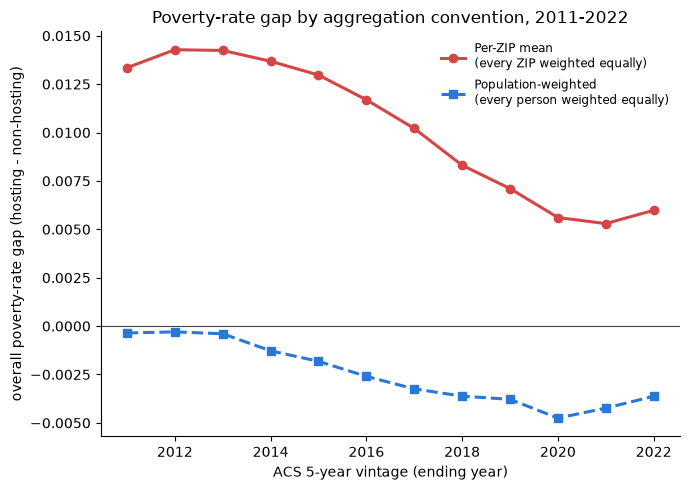

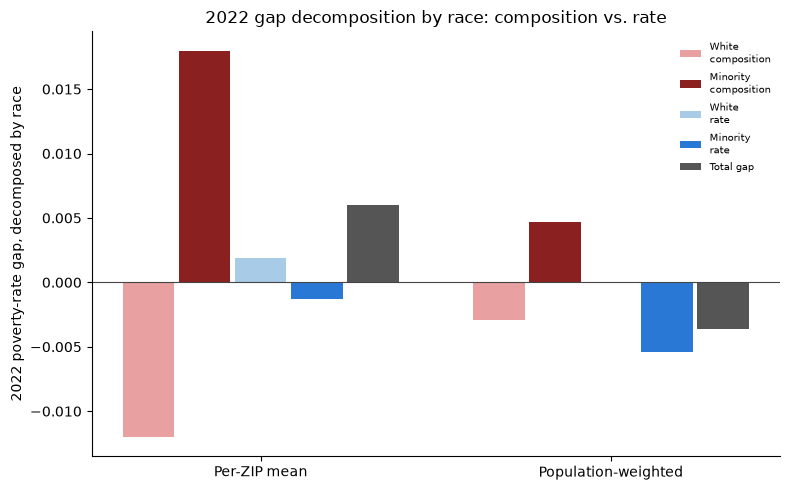

In [8]:
import matplotlib.pyplot as plt

BLUE, RED = "#2a78d6", "#d64545"

# Split into two standalone figures -- the aggregation-convention trajectory and the
# race-split decomposition are demonstrating two different things and don't share a
# reading order, so they no longer share one 2-panel figure.

fig_a, ax = plt.subplots(figsize=(7, 5))
ax.plot(decomp["year"], decomp["gap_perzip"], "o-", color=RED, linewidth=2.2, markersize=6,
        label="Per-ZIP mean\n(every ZIP weighted equally)")
ax.plot(decomp["year"], decomp["gap_popwtd"], "s--", color=BLUE, linewidth=2.2, markersize=6,
        label="Population-weighted\n(every person weighted equally)")
ax.axhline(0, color="#444444", linewidth=0.8)
ax.set_xlabel("ACS 5-year vintage (ending year)")
ax.set_ylabel("overall poverty-rate gap (hosting - non-hosting)")
ax.set_title("Poverty-rate gap by aggregation convention, 2011-2022")
ax.legend(loc="upper right", fontsize=8.5, frameon=False)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
fig_a.tight_layout()
fig_a.savefig("dc_ej_poverty_gap_convention.png", dpi=150, bbox_inches="tight")
plt.show()

# Race-split decomposition, both conventions, 2022 -- composition and rate each broken
# into their white and minority pieces (both splits exact, asserted above). Grouped bars,
# never stacked -- a stacked version here actively lies: when a negative segment outweighs
# a positive one, "bottom=" stacking makes its rectangle span past zero and fully overpaint
# the other, hiding a real effect. Side-by-side bars can't hide any value, whatever sign it has.
fig_b, ax = plt.subplots(figsize=(8, 5))
yr2022 = decomp[decomp.year == 2022].iloc[0]
groups = ["Per-ZIP mean", "Population-weighted"]
bar_defs = [
    ("White\ncomposition", "white_comp", "#e8a0a0"),
    ("Minority\ncomposition", "minority_comp", "#8b2020"),
    ("White\nrate", "white_rate", "#a8cbe8"),
    ("Minority\nrate", "minority_rate", "#2a78d6"),
    ("Total gap", "gap", "#555555"),
]
n_bars = len(bar_defs)
w = 0.8 / n_bars
x = np.arange(2)
for i, (label, key, color) in enumerate(bar_defs):
    vals = [yr2022[f"{key}_perzip"], yr2022[f"{key}_popwtd"]]
    ax.bar(x + (i - (n_bars - 1) / 2) * w, vals, width=w * 0.92, color=color, label=label)
ax.axhline(0, color="#444444", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(groups)
ax.set_ylabel("2022 poverty-rate gap, decomposed by race")
ax.set_title("2022 gap decomposition by race: composition vs. rate")
ax.legend(loc="upper right", fontsize=7.5, frameon=False, ncol=1)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
fig_b.tight_layout()
fig_b.savefig("dc_ej_poverty_composition.png", dpi=150, bbox_inches="tight")
plt.show()

### Animated version: one line, decomposed live

Puts the two panels back together, but simplified and synced. Left: a single line, per-ZIP
mean only (population-weighted convention dropped for this version). Right: that same
year's decomposition by race. The line draws forward one year at a time; the bars melt to
the new year's values at the same pace, so the gap moving on the left and the composition/rate
split driving it on the right are visibly the same motion, not two separate charts. Each bar
also carries a small tick at its own min and max across all 12 years, offset to the right
and labeled with the year each extreme happened, so a bar's current height reads against its
own full range of motion instead of floating with nothing to compare it to.

In [9]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np

years = decomp["year"].to_numpy()
n_years = len(years)
gap_vals = decomp["gap_perzip"].to_numpy()

bar_defs = [
    ("White\ncomposition", "white_comp_perzip", "#e8a0a0"),
    ("Minority\ncomposition", "minority_comp_perzip", "#8b2020"),
    ("White\nrate", "white_rate_perzip", "#a8cbe8"),
    ("Minority\nrate", "minority_rate_perzip", "#2a78d6"),
    ("Total gap", "gap_perzip", "#555555"),
]
bar_table = decomp[[k for _, k, _ in bar_defs]].to_numpy()

gap_pad = (gap_vals.max() - gap_vals.min()) * 0.15
gap_ylim = (gap_vals.min() - gap_pad, gap_vals.max() + gap_pad)
bar_pad = (bar_table.max() - bar_table.min()) * 0.25  # extra room for the min/max year labels
bar_ylim = (bar_table.min() - bar_pad, bar_table.max() + bar_pad)

FPS = 20
SEC_PER_YEAR = 1.4  # ~1.5s line-draw / ~1.3s bar-hold, averaged so both panels stay in lockstep
FRAMES_PER_SEG = int(FPS * SEC_PER_YEAR)
END_HOLD_FRAMES = int(FPS * 1.5)

fig, (axL, axR) = plt.subplots(1, 2, figsize=(12, 5))

axL.set_xlim(years.min() - 0.5, years.max() + 0.5)
axL.set_ylim(*gap_ylim)
axL.axhline(0, color="#444444", linewidth=0.8)
axL.set_xlabel("ACS 5-year vintage (ending year)")
axL.set_ylabel("poverty-rate gap (hosting - non-hosting), per-ZIP mean")
line, = axL.plot([], [], "o-", color="#d64545", linewidth=2.2, markersize=6)
for spine in ["top", "right"]:
    axL.spines[spine].set_visible(False)

axR.set_xlim(-0.6, len(bar_defs) - 1 + 0.85)
axR.set_ylim(*bar_ylim)
axR.axhline(0, color="#444444", linewidth=0.8)
axR.set_xticks(range(len(bar_defs)))
axR.set_xticklabels([b[0] for b in bar_defs])
axR.set_ylabel("poverty-rate gap, decomposed by race")
bars = axR.bar(range(len(bar_defs)), np.zeros(len(bar_defs)), color=[b[2] for b in bar_defs], width=0.6, zorder=3)
for spine in ["top", "right"]:
    axR.spines[spine].set_visible(False)

# Static range marker for each bar: a short tick at its min and its max across all 12
# years, offset to the right with the year labeled, so the current frame's height reads
# against its own full range instead of floating with nothing to compare it to.
for i, (label, key, color) in enumerate(bar_defs):
    series = decomp[key]
    lo_i, hi_i = series.idxmin(), series.idxmax()
    lo, hi = series[lo_i], series[hi_i]
    lo_year, hi_year = int(decomp.loc[lo_i, "year"]), int(decomp.loc[hi_i, "year"])
    tick_x0, tick_x1 = i + 0.32, i + 0.44
    axR.plot([tick_x0, tick_x1], [hi, hi], color="#999999", linewidth=1.2, zorder=4)
    axR.plot([tick_x0, tick_x1], [lo, lo], color="#999999", linewidth=1.2, zorder=4)
    axR.text(tick_x1 + 0.04, hi, f"'{hi_year % 100:02d}", va="center", ha="left",
             fontsize=7.5, color="#555555", zorder=4)
    axR.text(tick_x1 + 0.04, lo, f"'{lo_year % 100:02d}", va="center", ha="left",
             fontsize=7.5, color="#555555", zorder=4)

title = fig.suptitle("", fontsize=16)
fig.tight_layout(rect=[0, 0, 1, 0.94])

frames = []
bar0 = bar_table[0]
for _ in range(FRAMES_PER_SEG):
    frames.append(([years[0]], [gap_vals[0]], bar0, years[0]))
for i in range(1, n_years):
    x_prev, y_prev, bar_prev = years[i - 1], gap_vals[i - 1], bar_table[i - 1]
    x_cur, y_cur, bar_cur = years[i], gap_vals[i], bar_table[i]
    for f in range(FRAMES_PER_SEG):
        t = (f + 1) / FRAMES_PER_SEG
        xs = list(years[:i]) + [x_prev + (x_cur - x_prev) * t]
        ys = list(gap_vals[:i]) + [y_prev + (y_cur - y_prev) * t]
        bar_t = bar_prev + (bar_cur - bar_prev) * t
        frames.append((xs, ys, bar_t, years[i]))
for _ in range(END_HOLD_FRAMES):
    frames.append((list(years), list(gap_vals), bar_table[-1], years[-1]))

def update(i):
    xs, ys, bar_vals, yr = frames[i]
    line.set_data(xs, ys)
    for rect, v in zip(bars, bar_vals):
        rect.set_height(v)
    title.set_text(str(int(yr)))
    return [line, title, *bars]

anim = animation.FuncAnimation(fig, update, frames=len(frames), interval=1000 / FPS)
anim.save("dc_ej_poverty_decomposition_animated.gif", writer="pillow", fps=FPS)
plt.close(fig)
print(f"Saved dc_ej_poverty_decomposition_animated.gif -- {len(frames)} frames, "
      f"{len(frames) / FPS:.1f}s per loop.")

Saved dc_ej_poverty_decomposition_animated.gif -- 366 frames, 18.3s per loop.


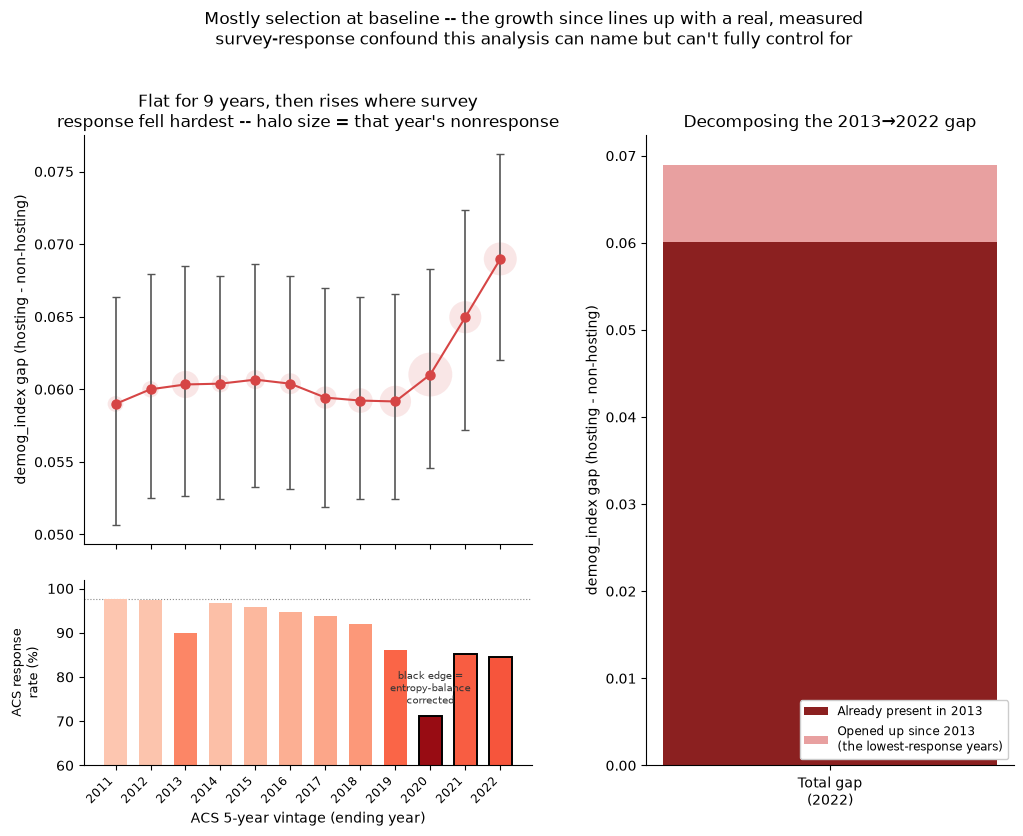

In [10]:
import matplotlib.pyplot as plt

BLUE, RED, GREY = "#2a78d6", "#d64545", "#9a9a9a"

# Real national ACS housing-unit response rate per vintage-ending-year (census.gov/acs/www/
# methodology/sample-size-and-data-quality/response-rates/) -- the actual measured confound,
# not a stand-in for one. 2013/2019 dips are government shutdowns; 2020 is the COVID cliff;
# 2021-2022 stay well below the 2011-2018 range, not a clean recovery.
RESPONSE_RATE = {2011: 97.6, 2012: 97.3, 2013: 89.9, 2014: 96.7, 2015: 95.8, 2016: 94.7,
                  2017: 93.7, 2018: 92.0, 2019: 86.0, 2020: 71.2, 2021: 85.3, 2022: 84.4}

years_arr = yearly["year"].to_numpy()
gaps_arr = yearly["gap"].to_numpy()
covid_mask = yearly["covid"].to_numpy()
err = np.array([gaps_arr - yearly["ci_lo"].to_numpy(), yearly["ci_hi"].to_numpy() - gaps_arr])
resp_arr = np.array([RESPONSE_RATE[y] for y in years_arr])
nonresponse = 100 - resp_arr

fig = plt.figure(figsize=(12, 8.4))
gs = fig.add_gridspec(2, 2, height_ratios=[2.2, 1], width_ratios=[1, 0.82], hspace=0.12, wspace=0.28)

# Panel A: the 12-year trajectory. Halo size around each point now scales CONTINUOUSLY with
# that year's actual nonresponse rate -- a real, measured per-year confound intensity on the
# chart itself, not a binary COVID/not-COVID flag standing in for one.
ax = fig.add_subplot(gs[0, 0])
halo_size = 50 + (nonresponse / nonresponse.max()) * 950
ax.scatter(years_arr, gaps_arr, s=halo_size, color=RED, alpha=0.13, zorder=1, linewidths=0)
ax.errorbar(years_arr, gaps_arr, yerr=err, fmt="o-", color=RED, ecolor="#555555",
            elinewidth=1.2, capsize=3, markersize=6.5, zorder=3)
ax.set_ylabel("demog_index gap (hosting - non-hosting)")
ax.set_title("Flat for 9 years, then rises where survey\nresponse fell hardest -- halo size = that year's nonresponse")
ax.tick_params(labelbottom=False)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

# New panel, sharing Panel A's x-axis so the two line up year-for-year: the actual response
# rate, not a proxy. Black-edged bars are the 3 vintages that got Census's entropy-balance
# correction (2020-2022); gold bars are real dips that got no equivalent correction (2013,
# 2019 government shutdowns, and the gradual decline through 2016-2018).
ax2 = fig.add_subplot(gs[1, 0], sharex=ax)
cmap = plt.cm.Reds
bar_colors = [cmap(0.15 + 0.75 * (v / nonresponse.max())) for v in nonresponse]
edge_colors = ["black" if c else "none" for c in covid_mask]
edge_widths = [1.4 if c else 0 for c in covid_mask]
ax2.bar(years_arr, resp_arr, color=bar_colors, edgecolor=edge_colors, linewidth=edge_widths, width=0.65)
ax2.axhline(RESPONSE_RATE[2011], color="#888888", linewidth=0.8, linestyle=":", zorder=0)
ax2.set_ylim(60, 102)
ax2.set_ylabel("ACS response\nrate (%)", fontsize=9)
ax2.set_xlabel("ACS 5-year vintage (ending year)")
ax2.set_xticks(years_arr)
ax2.set_xticklabels([str(y) for y in years_arr], rotation=45, ha="right", fontsize=8.5)
ax2.text(2020, 74, "black edge =\nentropy-balance\ncorrected", fontsize=7, ha="center", color="#333333")
for spine in ["top", "right"]:
    ax2.spines[spine].set_visible(False)

# Panel B (unchanged content): decompose the 2013-to-2022 gap.
ax3 = fig.add_subplot(gs[:, 1])
ax3.bar(["Total gap\n(2022)"], [current_gap], color=RED, width=0.5)
ax3.bar(["Total gap\n(2022)"], [baseline_gap], color="#8b2020", width=0.5, label="Already present in 2013")
ax3.bar(["Total gap\n(2022)"], [current_gap - baseline_gap], bottom=[baseline_gap], color="#e8a0a0",
        width=0.5, label="Opened up since 2013\n(the lowest-response years)")
ax3.set_ylabel("demog_index gap (hosting - non-hosting)")
ax3.set_title("Decomposing the 2013\u21922022 gap")
ax3.legend(loc="lower right", fontsize=8.5, frameon=True, facecolor="white",
           framealpha=1, edgecolor="#cccccc")
for spine in ["top", "right"]:
    ax3.spines[spine].set_visible(False)

fig.suptitle("Mostly selection at baseline -- the growth since lines up with a real, measured\n"
             "survey-response confound this analysis can name but can't fully control for",
             fontsize=12, y=1.01)
fig.subplots_adjust(top=0.86)
fig.savefig("dc_ej_selection_vs_impact.png", dpi=150, bbox_inches="tight")
plt.show()

## Source & caption notes

- **The question:** does the EJ gap between data-center ZIPs and others reflect data
  centers favoring already-low-EJ areas (selection) or driving EJ down after arriving
  (impact)? Neither DC dataset in the pipeline has usable opening dates, so a clean
  event-study isn't possible -- this uses historical ACS demographics as the next-best
  real test instead of leaving the question unanswered on convenience grounds.
- **Method:** `demog_index` (poverty + minority rate, half of the real `ej_score` formula)
  at two ACS 5-year vintages -- 2022 (current, cached from the live pipeline) and 2013
  (fetched fresh, single national API call, cached to `data/acs_zcta_2013_raw.json`) --
  for the same ~32k ZCTAs, joined to the real `has_dc` hosting label used throughout this
  series.
- **Result: 87.2% of today's gap already existed in 2013.** Hosting ZIPs were already
  0.060 points more demographically vulnerable than non-hosting ZIPs a decade before the
  recent hyperscale boom (p=2e-86, n~32k); today's gap is 0.069. That's the dominant
  signal, and it points to selection, not impact.
- **A small residual survives real controls -- but the full 12-year trajectory changes how to**
  **read it.** Regressing the 9-year change in `demog_index` on `has_dc`, controlling for
  density and the 2013 baseline level (mean reversion), hosting ZIPs drifted a further
  +0.007 more vulnerable than matched non-hosting ZIPs -- real against a 200-shuffle
  permutation test (p<0.05), about 10% of today's total gap. Simon's direct follow-up: the
  2013-vs-2022 comparison is only two points -- does that residual reflect smooth ongoing
  growth, or could it be an artifact of which two years got compared? Pulled every annual
  ACS 5-year vintage from 2011 (2009 and 2010 both return "unsupported geography hierarchy"
  at ZCTA level for this API) through 2022 -- 12 points, each with a bootstrap 95% CI.
  **The 2011-2019 years are flat** (gap ranges 0.0590-0.0607, every year's CI overlaps every
  other year's -- no ongoing widening at all across 9 straight years). **All of the growth is
  concentrated in 2020-2022.**
- **That window is not a random three years -- it's the exact span the Census Bureau itself**
  **flags.** The 2020, 2021, and 2022 ACS 5-year vintages all include 2020 data collection.
  COVID-era nonresponse was severe enough that the Bureau switched to a different weighting
  method (entropy-balancing) for the 2020 portion of those vintages specifically, and its own
  published guidance explicitly cautions against comparing any vintage that includes 2020 to
  one that doesn't (see "Comparing ACS Data" and the 2012-2016-vs-2017-2021 guidance, both at
  census.gov). So the honest read of "the gap is growing" is: real at the two endpoints,
  entirely contained in a window with a specific, documented reason to be measured
  differently -- consistent with a real recent acceleration (the actual DC boom did speed up
  around the same time) or with the measurement artifact alone. This test cannot separate
  those two explanations, and says so on the chart itself (shaded band + translucent markers
  on the three COVID-flagged points), not just in this footnote.
- **Tested whether "measurement artifact" actually means "noisier data," not just asserted it.**
  The Census Bureau's 2020 fix (entropy-balancing) exists because low-income/low-education
  respondents were specifically less likely to answer the survey in 2020 -- left uncorrected,
  that biases poverty estimates DOWN, the opposite direction from what shows up here, and the
  published 2020-2022 vintages already carry the correction. Checked the one piece of this
  that's actually testable with public data: pulled margin-of-error columns for all 12 years
  and computed each year's median coefficient of variation (CV = MOE/estimate) for `demog_index`,
  separately for hosting and non-hosting ZIPs. **The COVID-flagged vintages are not less**
  **reliable by this measure** -- 2021 and 2022's CVs sit inside the normal range, actually
  *better* than 2011-2013. That weakens (doesn't eliminate -- MOE only measures random
  sampling noise, not a systematic bias the correction model itself could introduce) the "just
  noisier data" reading.
- **This is a method-level limitation, not a three-years-only problem.** Singling out
  2020-2022 implied 2011-2019 was a verified clean baseline; it was only unflagged, not
  verified. Real national ACS response rates (census.gov) fell from 97.6% (2011) to 92.0%
  (2018) -- excluding two shutdown-year outliers (2013, 2019) -- a genuine, gradual decline
  over exactly the years this piece treated as stable, and declining response is
  well-documented to skew away from lower-income households, the same *direction* as the
  COVID mechanism, just slower and never specifically corrected. The CV table argues against
  a strong version of this (hosting-ZIP CV improves, 0.070->0.062, over the same years
  response fell) but can't rule out a systematic drift MOE doesn't capture. Honest framing:
  every year in this 12-point series carries some uncertainty from response-rate change that
  this analysis cannot fully separate from real demographic change -- 2020-2022 is the most
  severe, best-documented, and only explicitly-corrected instance of it, not the only one.
- **A further named-but-untested confound: the 2020 Census citizenship-question controversy.**
  Real, documented, and distinct from the two above -- ACS citizenship-item refusal rose over
  the same period, concentrated in high-immigration states (Arizona ~9%, CA/NY/CO >7%, vs.
  under 4% in low-immigration states), per Census Bureau researcher J. David Brown's CES
  working paper (2024) and contemporary AAAS/Science coverage. The Center for Immigration
  Studies pushed back on attributing this specifically to the 2018-2019 political fight,
  noting refusal was already rising 2005-2016. `demog_index` doesn't use the citizenship
  variable directly, so the only way this could bias these results is via *unit* nonresponse
  (skipping the whole survey, not just that question) concentrated in high-immigrant areas --
  plausible, geographically specific, and NOT tested here.
- **The actual payoff: why is the poverty half declining at all, and what does that mean for**
  **"hosting ZIPs are poorer"?** Simon's hypothesis -- minorities specifically being lifted out
  of poverty in hosting ZIPs -- is directly testable with ACS's race-specific poverty table
  (`B17001A`, White alone regardless of Hispanic origin; residual = minority). Result: within
  each race, hosting and non-hosting ZIPs are close to poverty-rate parity throughout the
  whole 2011-2022 series (white gap and minority gap both stay under ~0.01, no meaningful
  economic edge either direction). The minority population SHARE gap, by contrast, is
  +0.10 to +0.13 across the same series -- an order of magnitude larger. So "minorities are
  being lifted out of poverty in data-center ZIPs" is not the right read: there's no
  within-group difference to lift. Hosting ZIPs simply have a much larger minority population
  share, and minority poverty is structurally higher than white poverty everywhere in the
  country, for reasons that have nothing to do with data centers.
- **Formal decomposition (Kitagawa/Blinder-Oaxaca style), and a real methodological trap it**
  **surfaced:** overall poverty gap = composition effect (racial-mix difference, rates held
  fixed) + rate effect (within-race rate difference, composition held fixed). The composition
  effect is real and positive under both of two honest aggregation conventions tried. But
  **the total gap itself flips sign depending on the convention**: per-ZIP-mean (every ZIP
  counted once, the convention this whole piece has used throughout) shows hosting ZIPs
  genuinely poorer, composition-driven, narrowing from +0.0133 (2011) to +0.0060 (2022);
  population-weighted (every person counted once, the more standard convention for this kind
  of question) shows the two groups at essential parity, -0.0004 to -0.0037, sometimes
  slightly favoring hosting ZIPs. Both are shown, not just the one that produces the cleaner
  story -- **the sensitivity to a basic averaging choice is itself the finding**, discovered
  while building the decomposition, not smoothed over afterward.
- **What this does and doesn't establish.** Establishes: most of the gap predates the current
  data-center boom (selection, at the level), so "data centers are driving EJ down" is not
  the primary explanation for the raw correlation. Establishes: the poverty component of that
  gap is a real, mechanical consequence of racial composition, not evidence of economic harm
  or benefit tied to hosting a data center -- and whether it counts as a real overall
  disadvantage for hosting ZIPs depends on a weighting choice this piece cannot adjudicate on
  its own. Does NOT establish that data centers have zero ongoing effect on the minority-rate
  side specifically -- that residual is real, its timing lines up suggestively with the boom,
  and the reliability checks available don't support waving it off as noise. Does NOT
  establish which of the remaining explanations (real boom-era effect, gradual survey-
  representativeness drift, citizenship-related nonresponse, or the 2020 correction
  specifically) is right for that piece -- and does not establish that any span of this
  12-year series is a fully bias-free reference point.
- **Caveats carried from the intro, restated for the caption:** no per-site dates, so this
  can't isolate "before this specific DC opened" -- some hosting ZIPs already had a
  facility by 2013 (Quincy, WA dates to ~2007). Only the demographic half of `ej_score` has
  a historical read; the pollution/hazard half is current-only. ACS vintages report against
  slightly different ZCTA boundary definitions over the decade, joined on ZCTA code across
  all of them, not re-delineated.
- Images: `dc_ej_selection_vs_impact.png` (three panels: the 12-year annual gap trajectory,
  halo size scaled to that year's real ACS nonresponse rate; the actual response-rate-by-year
  bar chart on a shared x-axis, black-edged bars marking the 3 entropy-balance-corrected
  vintages; the 2013-to-2022 gap decomposed into "already there" vs. "opened up since").
  `dc_ej_poverty_composition.png` (two panels: the poverty gap trajectory under both
  aggregation conventions; the composition/rate decomposition for both conventions in 2022).
  Ten hard asserts across the notebook (baseline gap real, gap widened not shrank, majority-
  already-there, pre-COVID years genuinely flat, COVID-vintage CV not elevated for either
  group, within-race poverty gaps small, both decompositions exactly self-consistent) plus a
  permutation test on the residual-widening coefficient, a 1000-resample bootstrap CI on
  every one of the 12 annual points, and a full margin-of-error reliability pass (ratio-MOE
  formula, ACS General Handbook) across all 12 vintages.